In [1]:
import tensorflow as tf
import keras

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import image_dataset_from_directory, load_img, img_to_array
from tensorflow.keras import layers

import numpy as np

import matplotlib.pyplot as plt
from matplotlib import cm

# Constants

In [2]:
IMG_SIZE    = (256, 256)
CHANNELS    = 3
BATCH_SIZE  = 32
EPOCHS      = 20

CONV2D_FILTERS = 32
KERNEL_SIZE    = (3, 3)
POOL_SIZE      = (2, 2)
DENSE_UNITS    = 128
DROPOUT_RATE   = 0.5

ACTIVATION             = 'relu'
FINAL_DENSE_ACTIVATION = 'sigmoid'
OPTIMIZER = 'adam'
LOSS      = 'binary_crossentropy'
METRICS   = ['accuracy']

VAL_SPLIT = .2

# Build

In [3]:
classifier = Sequential([
    layers.Rescaling(1./255, input_shape=(*IMG_SIZE, CHANNELS)),

    Conv2D(CONV2D_FILTERS, KERNEL_SIZE, activation=ACTIVATION),
    MaxPooling2D(pool_size=POOL_SIZE),

    Conv2D(CONV2D_FILTERS, KERNEL_SIZE, activation=ACTIVATION),
    MaxPooling2D(pool_size=POOL_SIZE),

    Flatten(),

    Dense(DENSE_UNITS, activation=ACTIVATION),
    layers.Dropout(DROPOUT_RATE),
    Dense(1, activation=FINAL_DENSE_ACTIVATION),
])

classifier.compile(optimizer=OPTIMIZER, loss=LOSS, metrics=METRICS)

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


# Train

In [4]:
# train / test split
train_dataset, test_dataset = image_dataset_from_directory(
    "Data", labels='inferred', label_mode='binary',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    validation_split=VAL_SPLIT, subset='both',
    shuffle=True, seed=19)

# add early stopping
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                           restore_best_weights=True)]

# train the model
history = classifier.fit(train_dataset, validation_data=test_dataset,
                         epochs=EPOCHS, callbacks=callbacks)

Found 195 files belonging to 2 classes.
Using 156 files for training.
Using 39 files for validation.
Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 353ms/step - accuracy: 0.4881 - loss: 6.1211 - val_accuracy: 0.8462 - val_loss: 0.3559
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 273ms/step - accuracy: 0.6453 - loss: 2.1378 - val_accuracy: 0.7179 - val_loss: 0.9150
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 277ms/step - accuracy: 0.7588 - loss: 1.0242 - val_accuracy: 0.8462 - val_loss: 0.3550
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 266ms/step - accuracy: 0.9154 - loss: 0.2118 - val_accuracy: 0.8718 - val_loss: 0.1855
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 266ms/step - accuracy: 0.9641 - loss: 0.1084 - val_accuracy: 0.8205 - val_loss: 0.2779
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 267ms/step - accuracy: 0.9663 - loss: 0.0851 - val_accuracy: 0.9231 - val_loss: 0.2020
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 265ms/step - accuracy: 0.9823 - loss: 0.0487 - val_accuracy: 0.9231 - val_loss: 0.1984
Epoch 8/20
5/5 ━━

# Classify

Elephant (87.79% confidence)


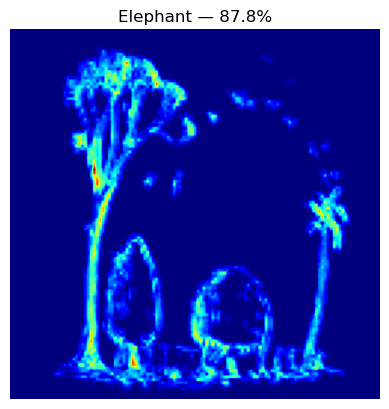

In [5]:
# classify the image
img_array = img_to_array(load_img("../Test Images/Real Test.png", target_size=IMG_SIZE))[None, ...]

score = float(classifier.predict(img_array, verbose=0)[0][0])
idx   = int(score > 0.5)
label = "Water bottle" if idx else "Elephant"
conf  = score if idx else 1 - score
print(f"{label} ({conf:.2%} confidence)")

# rebuild as a graph that also returns the conv feature maps
LAST_CONV = [l.name for l in classifier.layers if isinstance(l, Conv2D)][-1]

inputs = keras.Input(shape=(*IMG_SIZE, CHANNELS))
x, conv_out = inputs, None
for layer in classifier.layers:
    x = layer(x)
    if layer.name == LAST_CONV:
        conv_out = x
grad_model = keras.Model(inputs, [conv_out, x])

# Grad-CAM
with tf.GradientTape() as tape:
    conv_out, preds = grad_model(tf.cast(img_array, tf.float32), training=False)
    tape.watch(conv_out)
    target = preds[:, 0] if idx else -preds[:, 0]

weights = tf.reduce_mean(tape.gradient(target, conv_out), axis=(0, 1, 2))
heatmap = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))
heatmap = (heatmap / (tf.reduce_max(heatmap) + 1e-8)).numpy()

# show the heatmap
plt.imshow(heatmap, cmap='jet')
plt.title(f'{label} — {conf:.1%}')
plt.axis('off')
plt.show()